In [1]:
import numpy as np
import sympy as sm
import pandas as pd

import scipy as sp
from scipy.integrate import solve_ivp
import scipy.optimize as optimize

import matplotlib as mp
import matplotlib.pyplot as plt
import seaborn as sns

import os
from tqdm import tqdm
import glob

In [2]:
def dydt(t, y, par):

    par = np.abs(par)

    alpha = par[0]
    beta  = par[1]

    S = y[0]
    I = y[1]
    R = y[2]
    C = y[3]

    dS =  -beta*S*I
    dI = beta*S*I - alpha*I
    dR = alpha*I
    dC = beta*S*I

    return np.array([dS,dI,dR,dC])

# Solve the ODE model using solve_ivp


def SolveModel(par,tspan,init_cond,t_eval):

    ode_soln = solve_ivp(dydt,
                         tspan,
                         init_cond,
                         t_eval = t_eval,
                         args = (par,))
    return ode_soln

In [3]:
# Define initial conditions
N0 = 1000
I0 = 5
R0 = 0
C0 = 0
S0 = N0 - I0 - R0
init_cond = np.array([S0, I0, R0, C0])

#Define time variables
t_final=100
tspan = (1,t_final)
t_eval = np.arange(1, 101)  # instead of linspace or floats
tdata = np.arange(0,t_final)

In [4]:
params_df = pd.read_csv('../data/params_combos.csv')

In [5]:
params_df["R0"] = (params_df["Beta"] * 1000 / params_df["Alpha"]).round(2) #Calculate R0
params_df = params_df.sort_values("R0").reset_index(drop=True) #Sort df by R0

# Load trajectory files and map to params_df
data_dir = '../data/ctmc_trajectories' #Load data
csv_files = sorted(glob.glob(os.path.join(data_dir, '*.csv')))
param_to_file = {}
for file in csv_files:
    name = os.path.basename(file).replace('.csv', '').replace("alpha", "").replace("beta", "")
    parts = name.split("_")
    alpha = float(parts[0].replace("p", "."))
    beta = float(parts[1].replace("p", "."))
    param_to_file[(alpha, beta)] = file

In [6]:
## for each parameter combination, calculate the mean and variance of the trajectories at each time point t. Then plot variance vs mean.

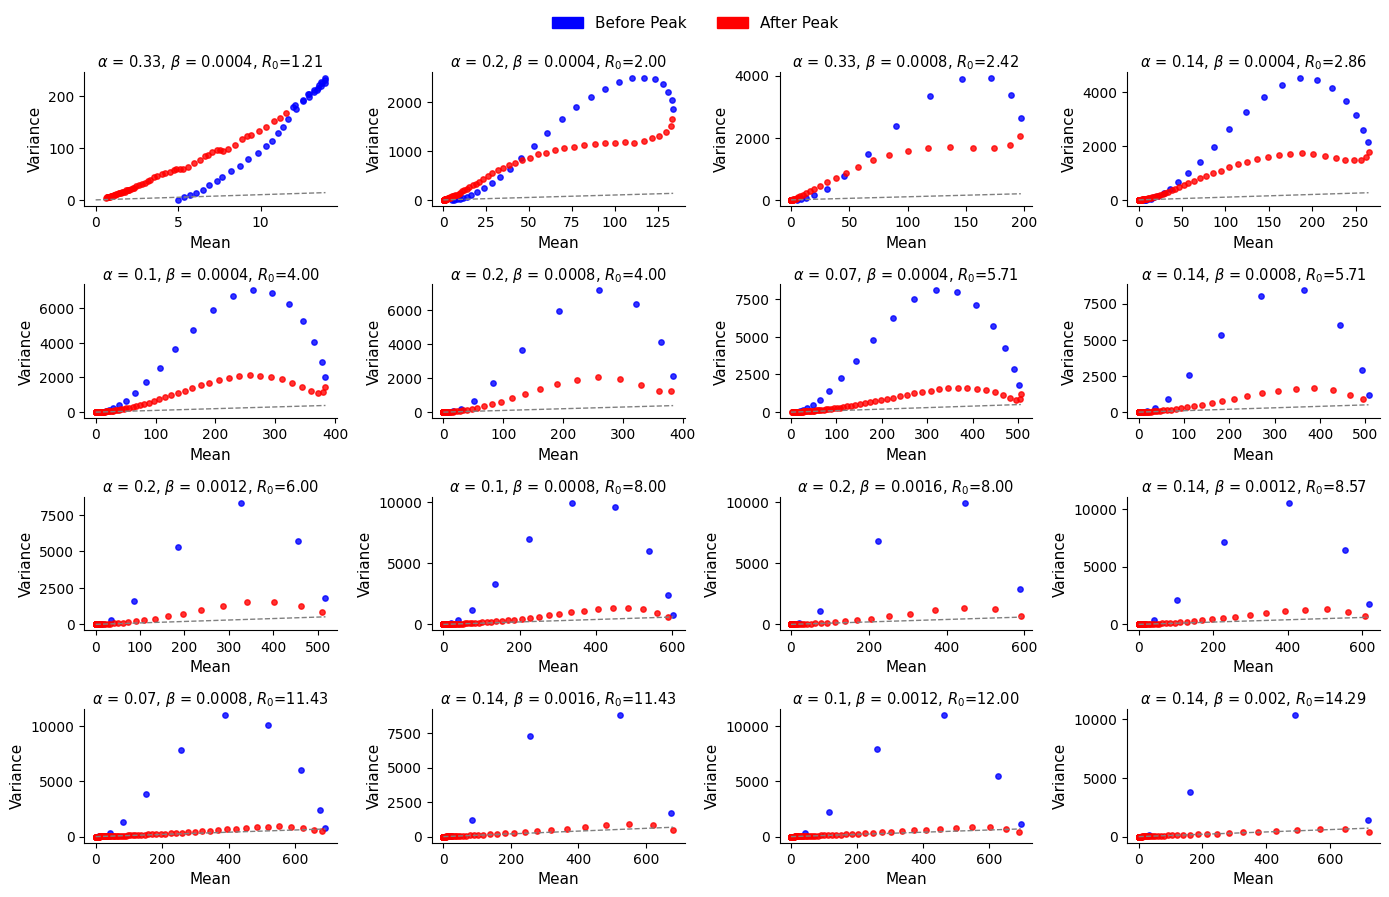

In [7]:
# === Variance vs Mean per timepoint, color-coded relative to ODE peak ===
import matplotlib.patches as mpatches

num_plots = len(params_df)
num_cols = 4
num_rows = int(np.ceil(num_plots / num_cols))

fig, ax = plt.subplots(num_rows, num_cols, figsize=(14, 9))
ax = ax.flatten()

for idx, row in params_df.iterrows():
    alpha = float(row["Alpha"])
    beta  = float(row["Beta"])
    R0    = row["R0"]
    par   = (alpha, beta)

    # Load CTMC data for this (alpha, beta)
    file = param_to_file.get((alpha, beta))
    if not file:
        ax[idx].set_title(f'α={alpha}, β={beta}\n(no data)', fontsize=12)
        ax[idx].axis('off')
        continue

    df = pd.read_csv(file)
    # Compute per-time mean and variance
    stats = (
        df.groupby("time")["I"]
          .agg(mean="mean", var="var", count="size")
          .reset_index()
          .fillna({"var": 0.0})
    )

    # Solve ODE to locate peak of I
    soln = SolveModel(par, tspan, init_cond, t_eval)
    I_ode = soln.y[1]
    t_peak = t_eval[np.argmax(I_ode)]

    # Split before/after ODE peak
    before = stats[stats["time"] <= t_peak]
    after  = stats[stats["time"] >  t_peak]

    # Plot before (blue) and after (red)
    ax[idx].scatter(before["mean"], before["var"], s=15, alpha=0.8, color="blue", label="Before ODE peak")
    ax[idx].scatter(after["mean"],  after["var"],  s=15, alpha=0.8, color="red",  label="After ODE peak")


    # Add Poisson reference line (x=y)
    max_mean = stats["mean"].max()
    ax[idx].plot([0, max_mean], [0, max_mean], linestyle="--", color="gray", linewidth=1)

    # Titles and labels
    ax[idx].set_title(f'$\\alpha$ = {alpha}, $\\beta$ = {beta}, $R_0$={R0:.2f}', fontsize=10.5, pad=1)
    ax[idx].set_xlabel('Mean', fontsize=11)
    ax[idx].set_ylabel('Variance', fontsize=11)
    #ax[idx].grid(True, linestyle='--', linewidth=0.5, alpha=0.5)

    ax[idx].spines['top'].set_visible(False)
    ax[idx].spines['right'].set_visible(False)

# Add shared legend
legend_patches = [
    mpatches.Patch(color='blue', label='Before Peak'),
    mpatches.Patch(color='red', label='After Peak')
]
fig.legend(
    handles=legend_patches,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.0),
    ncol=2,
    frameon=False, fontsize = 11
)

# Hide unused subplots
for j in range(idx + 1, len(ax)):
    fig.delaxes(ax[j])

fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()
